# Birth Weight Prediction Using Linear Regression

Original analysis, cleaned and documented for publication. Compare maternal weight and gestation predictors, inspect influential observations, and fit gestation plus smoking status. Saved statistical results come from the original notebook.

This is an educational association analysis, with in-sample model fit only. Removing cases 239 and 820 is retained as a sensitivity analysis, not a general recommendation. No clinical or causal conclusions are established.

## Setup and data

Install `requirements.txt` in your Python environment, then launch Jupyter from this repository. Obtain an authorized copy of the original CSV and place it in `data/babies_data.csv`. The dataset is omitted because redistribution permission has not been established. Raw-row previews have been removed from saved output; rerunning locally will display them.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import lmdiag

from sklearn.linear_model import LinearRegression

In [ ]:
from pathlib import Path

DATA_PATH = Path("data") / "babies_data.csv"
if not DATA_PATH.is_file():
    raise FileNotFoundError(f"Place the authorized dataset at {DATA_PATH.resolve()}. See README.md.")

babies = pd.read_csv(
    DATA_PATH,
    index_col=0
)

babies.head()

In [ ]:
babies.shape

(1174, 7)

## Baseline and maternal-weight model

In [ ]:
n = len(babies.index)

mom_weight = babies['mom.weight'].values.reshape(-1, 1)
birth_weight = babies['birth.weight'].values

print(n)
print(mom_weight.shape)
print(birth_weight.shape)

1174
(1174, 1)
(1174,)


In [ ]:
# Model 0: Intercept-only model
fit0 = LinearRegression().fit(
    np.ones((n, 1)),
    birth_weight
)

# Model 1: Mother's weight as predictor
fit1 = LinearRegression().fit(
    mom_weight,
    birth_weight
)

In [ ]:
fit1_sm = sm.OLS(
    babies['birth.weight'],
    sm.add_constant(babies['mom.weight'])
).fit()

print(fit1_sm.summary())

                            OLS Regression Results                            
Dep. Variable:           birth.weight   R-squared:                       0.024
Model:                            OLS   Adj. R-squared:                  0.023
Method:                 Least Squares   F-statistic:                     29.20
Date:                Mon, 26 Oct 2026   Prob (F-statistic):           7.89e-08
Time:                        15:19:52   Log-Likelihood:                -5065.4
No. Observations:                1174   AIC:                         1.013e+04
Df Residuals:                    1172   BIC:                         1.014e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        101.7539      3.319     30.655      0.0

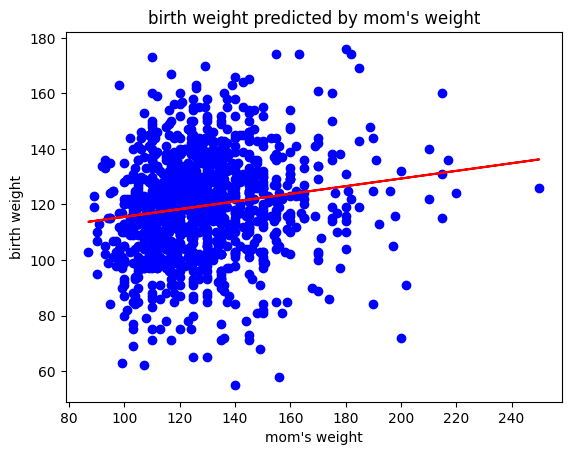

In [ ]:
plt.scatter(
    x=babies['mom.weight'],
    y=babies['birth.weight'],
    color='blue'
)

plt.xlabel("mom's weight")
plt.ylabel("birth weight")
plt.title("birth weight predicted by mom's weight")

plt.plot(
    mom_weight,
    fit1.predict(mom_weight),
    color='red'
)

plt.show()

## Gestation and influence diagnostics

In [ ]:
babies.corrwith(babies['birth.weight'])

birth.weight      1.000000
gestation         0.407543
not.first.born   -0.043908
mom.age           0.026983
mom.height        0.203704
mom.weight        0.155923
mom.smokes       -0.246800
dtype: float64

In [ ]:
gestation = babies['gestation'].values.reshape(-1, 1)

fit2 = LinearRegression().fit(gestation, birth_weight)

fit2_sm = sm.OLS(
    babies['birth.weight'],
    sm.add_constant(babies['gestation'])
).fit()

print(fit2_sm.summary())

                            OLS Regression Results                            
Dep. Variable:           birth.weight   R-squared:                       0.166
Model:                            OLS   Adj. R-squared:                  0.165
Method:                 Least Squares   F-statistic:                     233.4
Date:                Mon, 26 Oct 2026   Prob (F-statistic):           3.40e-48
Time:                        15:44:17   Log-Likelihood:                -4973.3
No. Observations:                1174   AIC:                             9951.
Df Residuals:                    1172   BIC:                             9961.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        -10.7541      8.537     -1.260      0.2

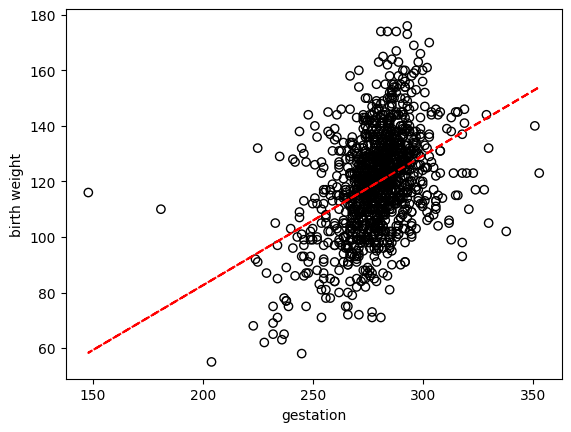

In [ ]:
plt.scatter(
    x=babies['gestation'],
    y=babies['birth.weight'],
    facecolors='none',
    edgecolors='black'
)

plt.plot(
    gestation,
    fit2.predict(gestation),
    linestyle='--',
    color='red'
)

plt.xlabel("gestation")
plt.ylabel("birth weight")
plt.show()

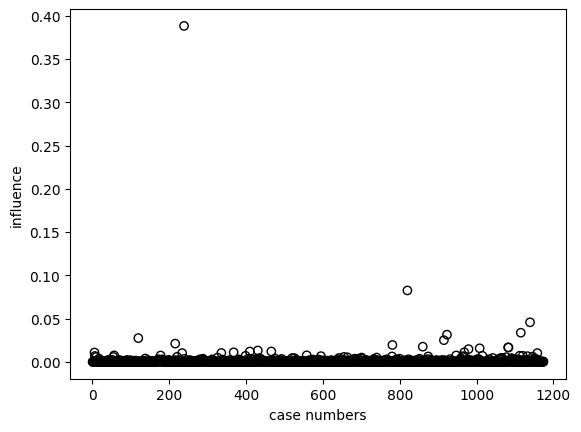

In [ ]:
case_numbers = babies.index

influence = pd.Series(
    fit2_sm.get_influence().cooks_distance[0],
    index=babies.index
)

plt.scatter(
    case_numbers,
    influence,
    facecolors='none',
    edgecolors='black'
)

plt.xlabel("case numbers")
plt.ylabel("influence")
plt.show()

In [ ]:
influence.sort_values(ascending=False).head()

239     0.388222
820     0.082582
1139    0.045751
1115    0.033731
923     0.031499
dtype: float64

## Sensitivity analysis and multiple regression

In [ ]:
babies2 = babies.drop([239, 820])

babies2.shape

(1172, 7)

In [ ]:
fit2_trimmed = sm.OLS(
    babies2['birth.weight'],
    sm.add_constant(babies2['gestation'])
).fit()

print(fit2_trimmed.summary())

                            OLS Regression Results                            
Dep. Variable:           birth.weight   R-squared:                       0.179
Model:                            OLS   Adj. R-squared:                  0.178
Method:                 Least Squares   F-statistic:                     254.8
Date:                Mon, 26 Oct 2026   Prob (F-statistic):           4.77e-52
Time:                        15:58:35   Log-Likelihood:                -4956.6
No. Observations:                1172   AIC:                             9917.
Df Residuals:                    1170   BIC:                             9927.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        -22.2026      8.888     -2.498      0.0

In [ ]:
X = babies2[['gestation', 'mom.smokes']]

fit3 = LinearRegression().fit(
    X,
    babies2['birth.weight']
)

print("Intercept:", fit3.intercept_)
print("Coefficients:", fit3.coef_)
print("R-squared:", fit3.score(X, babies2['birth.weight']))

Intercept: -13.648546114297119
Coefficients: [ 0.48809153 -8.17174744]
R-squared: 0.2259214941320512


## Residual diagnostics

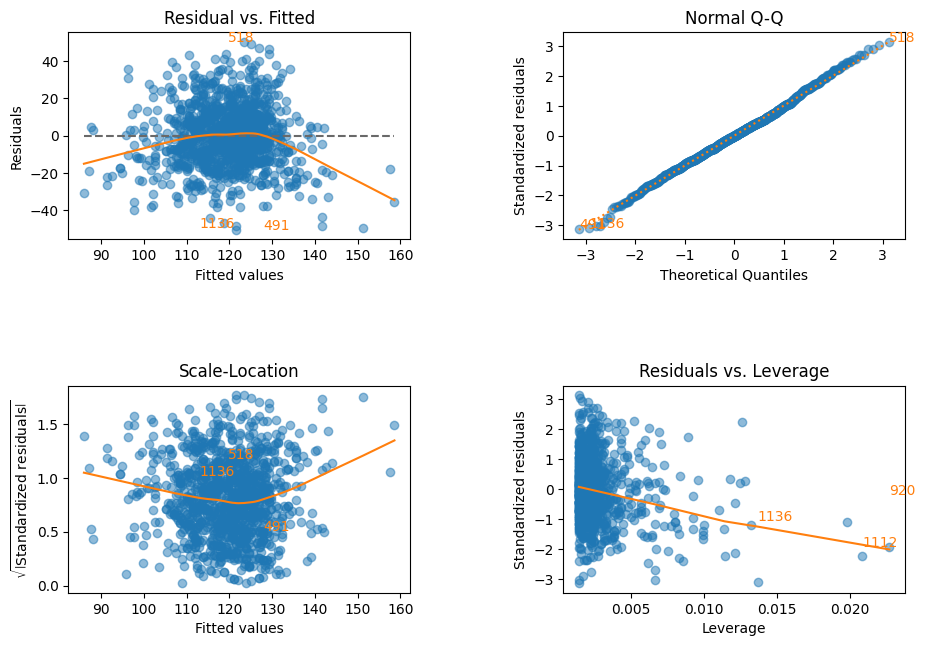

In [ ]:
fit3a = sm.OLS(
    babies2['birth.weight'],
    sm.add_constant(X)
).fit()

fig = lmdiag.plot(fit3a)
fig.set_size_inches(10, 7)
plt.show()

The Residuals vs Fitted plot shows residuals generally scattered around zero, but the smoothing line displays some curvature. This suggests possible deviations from the assumed linear relationship, particularly at the extremes of the fitted values.

The Normal Q-Q plot shows that the residuals closely follow the theoretical normal distribution, with only minor deviations at the tails. This suggests that the normality assumption is approximately satisfied.

The Scale-Location plot shows some curvature in the smoothing line, suggesting that the variance of the residuals may not be completely constant across fitted values. This indicates possible mild heteroscedasticity.

The Residuals vs Leverage plot shows that most observations have relatively low leverage. However, a few observations, including 920, 1136 and 1112, have higher leverage and may influence the fitted regression model. These observations should be investigated rather than automatically removed.

## Findings and limitations

The original maternal-weight model has R² ≈ 0.024; gestation alone has R² ≈ 0.166. After excluding the two influential cases, the gestation-plus-smoking model has in-sample R² = 0.2259, with coefficients approximately 0.4881 for gestation and −8.1717 for smoking status. These are associations in the source data. The existing residual interpretations are retained; no held-out prediction evaluation was performed.